# 01 – Dataset Exploration (PathSnap)
Goal: understand how the raw data is organised (partitions, trips, file types)
before designing any preprocessing.
Partitions available to us: `train` (80 trips) and `student_test` (10 trips).
The evaluator-testing partition is held by the organisers and is never used here.

In [ ]:
import os, glob, zipfile
import pandas as pd
import numpy as np

ZIP_PATH = "/content/Student folder.zip"
DATA_DIR = "/content/data"

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)

# Print the folder tree: depth 3, and only the first 5 files per folder
for root, dirs, files in os.walk(DATA_DIR):
    depth = root.replace(DATA_DIR, "").count(os.sep)
    if depth > 3: continue
    print("  " * depth + os.path.basename(root) + "/", f"({len(files)} files)")
    for f in sorted(files)[:5]:
        print("  " * (depth + 1) + f)

data/ (0 files)
  Student folder/ (0 files)
    student_test/ (0 files)
      00000076/ (4 files)
        00000076.arcs
        00000076.nodes
        00000076.route
        00000076.track
      00000009/ (4 files)
        00000009.arcs
        00000009.nodes
        00000009.route
        00000009.track
      00000065/ (4 files)
        00000065.arcs
        00000065.nodes
        00000065.route
        00000065.track
      00000077/ (4 files)
        00000077.arcs
        00000077.nodes
        00000077.route
        00000077.track
      00000052/ (4 files)
        00000052.arcs
        00000052.nodes
        00000052.route
        00000052.track
      00000007/ (4 files)
        00000007.arcs
        00000007.nodes
        00000007.route
        00000007.track
      00000000/ (4 files)
        00000000.arcs
        00000000.nodes
        00000000.route
        00000000.track
      00000091/ (4 files)
        00000091.arcs
        00000091.nodes
        00000091.route
        0000009

**What this does:** extracts the raw data and prints the directory structure.
**Why:** the guidelines warn not to assume every trip is identical, so we first
verify how partitions and trip files are actually named and organised.


In [ ]:
# One row per raw file: partition, trip id, file type, size
rows = []
for path in glob.glob(f"{DATA_DIR}/**/*", recursive=True):
    ext = os.path.splitext(path)[1]
    if ext in [".track", ".nodes", ".arcs", ".route"]:
        parts = path.split(os.sep)
        partition = "train" if "train" in parts else ("student_test" if "student_test" in parts else "unknown")
        rows.append({
            "partition": partition,
            "trip": os.path.splitext(os.path.basename(path))[0],
            "type": ext,
            "size_kb": round(os.path.getsize(path) / 1024, 1),
            "path": path,
        })
files = pd.DataFrame(rows)

print("Files per partition and type:")
print(files.groupby(["partition", "type"]).size().unstack(fill_value=0))

print("\nTrips per partition:")
print(files.groupby("partition")["trip"].nunique())

# Which file types each trip has (1 = present, 0 = missing)
avail = files.pivot_table(index=["partition", "trip"], columns="type",
                          values="size_kb", aggfunc="count", fill_value=0)
print("\nTrips missing at least one file type:")
print(avail[(avail == 0).any(axis=1)])

Files per partition and type:
type          .arcs  .nodes  .route  .track
partition                                  
student_test     10      10      10      10
train            80      80      80      80

Trips per partition:
partition
student_test    10
train           80
Name: trip, dtype: int64

Trips missing at least one file type:
Empty DataFrame
Columns: [.arcs, .nodes, .route, .track]
Index: []


**What this does:** builds an inventory of every raw file (partition, trip, type, size).
**Why:** required by the guidelines (trip counts, file availability, file sizes).
It also shows whether any trip is missing a file.


## 1. Loading a trip
Each trip folder has 4 whitespace-separated files with no headers:
- `.track`: lon, lat, timestamp (s), the noisy GPS observations
- `.nodes`: lon, lat; row index = node_id
- `.arcs`: from_node, to_node; row index = arc_id (a directed road segment)
- `.route`: sequence of arc_ids, the reference path

Important: `.route` is a sequence of road segments, not one label per GPS point.
GPS rows and road rows do not correspond one-to-one.

In [ ]:
import networkx as nx

DATA_ROOT = os.path.join(DATA_DIR, "Student folder")

def read_ws(path, names):
    """Read a whitespace-separated, header-less file. Empty file -> empty DataFrame."""
    try:
        return pd.read_csv(path, sep=r"\s+", header=None, names=names)
    except pd.errors.EmptyDataError:
        return pd.DataFrame(columns=names)

def load_trip(partition, trip_id):
    d = os.path.join(DATA_ROOT, partition, trip_id)
    p = lambda ext: os.path.join(d, trip_id + ext)
    track = read_ws(p(".track"), ["lon", "lat", "t"])
    nodes = read_ws(p(".nodes"), ["lon", "lat"])
    arcs  = read_ws(p(".arcs"),  ["u", "v"])        # u = from_node, v = to_node
    route = read_ws(p(".route"), ["arc_id"])
    return track, nodes, arcs, route

trips = {part: sorted(os.listdir(os.path.join(DATA_ROOT, part)))
         for part in ["train", "student_test"]}

# Look at one training trip
track, nodes, arcs, route = load_trip("train", trips["train"][0])
print("Trip:", trips["train"][0])
for name, df in [("track", track), ("nodes", nodes), ("arcs", arcs), ("route", route)]:
    print(f"\n{name}: shape={df.shape}")
    print(df.head(3)); print(df.dtypes.to_dict())

Trip: 00000001

track: shape=(1315, 3)
        lon        lat    t
0  8.595203  49.844053  1.0
1  8.595294  49.844441  2.0
2  8.595352  49.844883  3.0
{'lon': dtype('float64'), 'lat': dtype('float64'), 't': dtype('float64')}

nodes: shape=(88809, 2)
        lon        lat
0  8.581679  49.857880
1  8.584637  49.858295
2  8.580173  49.858567
{'lon': dtype('float64'), 'lat': dtype('float64')}

arcs: shape=(165790, 2)
   u    v
0  0  281
1  0    1
2  0    5
{'u': dtype('int64'), 'v': dtype('int64')}

route: shape=(525, 1)
   arc_id
0    2641
1   64973
2  133948
{'arc_id': dtype('int64')}


**What this does:** a loader that reads all 4 files of a trip with explicit column names.
**Why:** files have no headers, so we assign names from the dataset document and
verify the data types ourselves.
**Observation:** _(fill in: e.g. track has N rows; nodes/arcs sizes; dtypes as expected?)_

In [ ]:
def haversine_m(lon1, lat1, lon2, lat2):
    """Great-circle distance in metres. Lat/lon are angles, so we can't use
    Euclidean distance in degrees."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * 6371000 * np.arcsin(np.sqrt(a))

def trip_stats(partition, trip_id):
    track, nodes, arcs, route = load_trip(partition, trip_id)
    s = {"partition": partition, "trip": trip_id}

    # --- GPS track quality ---
    s["n_points"] = len(track)
    s["n_missing_rows"] = int(track.isna().any(axis=1).sum())
    lon, lat, t = track["lon"].values, track["lat"].values, track["t"].values
    s["n_invalid_coords"] = int(((np.abs(lat) > 90) | (np.abs(lon) > 180) | ((lat == 0) & (lon == 0))).sum())
    dt = np.diff(t)
    s["duration_s"] = t[-1] - t[0]
    s["pct_dt_1s"] = round(100 * np.mean(dt == 1), 1)
    s["n_dup_timestamps"] = int((dt == 0).sum())
    s["n_backwards_time"] = int((dt < 0).sum())
    s["n_gaps_gt5s"] = int((dt > 5).sum())
    s["max_gap_s"] = dt.max()
    step = haversine_m(lon[:-1], lat[:-1], lon[1:], lat[1:])
    s["length_km"] = round(step.sum() / 1000, 2)
    speed = step[dt > 0] / dt[dt > 0] * 3.6           # km/h
    s["max_speed_kmh"] = round(speed.max(), 1)
    s["n_stationary_steps"] = int((step == 0).sum())
    s["extent_km"] = round(haversine_m(lon.min(), lat.min(), lon.max(), lat.max()) / 1000, 2)

    # --- Road network ---
    s["n_nodes"], s["n_arcs"] = len(nodes), len(arcs)
    G = nx.DiGraph()
    G.add_nodes_from(range(len(nodes)))
    G.add_edges_from(zip(arcs["u"], arcs["v"]))
    s["n_isolated_nodes"] = sum(1 for n in G.nodes if G.degree(n) == 0)
    s["n_components"] = nx.number_weakly_connected_components(G)
    edge_set = set(zip(arcs["u"], arcs["v"]))
    s["pct_oneway_arcs"] = round(100 * np.mean([(v, u) not in edge_set for u, v in edge_set]), 1)
    s["n_self_loops"] = int((arcs["u"] == arcs["v"]).sum())
    s["n_duplicate_arcs"] = int(arcs.duplicated().sum())

    # --- Reference route ---
    r = route["arc_id"].values.astype(int)
    s["route_len_arcs"] = len(r)
    s["n_invalid_route_ids"] = int((r >= len(arcs)).sum())
    r = r[r < len(arcs)]
    U, V = arcs["u"].values, arcs["v"].values
    s["n_route_breaks"] = int((V[r[:-1]] != U[r[1:]]).sum())   # arc i must end where arc i+1 starts
    s["n_route_repeats"] = int((r[:-1] == r[1:]).sum())
    return s

stats = pd.DataFrame([trip_stats(p, t) for p in trips for t in trips[p]])
stats.to_csv("dataset_summary.csv", index=False)

pd.set_option("display.width", 200)
print("Coordinate ranges (to check column order: lat must be within ±90):")
all_tracks = pd.concat([load_trip(p, t)[0] for p in trips for t in trips[p]])
print(all_tracks.describe().loc[["min", "max"]])

print("\nSummary per partition:")
num_cols = stats.columns.drop(["partition", "trip"])   # leave out the text columns
print(stats.groupby("partition")[num_cols].agg(["mean", "min", "max"]).T.to_string())

Coordinate ranges (to check column order: lat must be within ±90):
            lon        lat         t
min -100.418538 -34.640291       1.0
max  137.237029  61.699590  154034.0

Summary per partition:
partition                 student_test          train
n_points            mean      1916.000    2605.212500
                    min        262.000     361.000000
                    max       3958.000   19313.000000
n_missing_rows      mean         0.000       0.000000
                    min          0.000       0.000000
                    max          0.000       0.000000
n_invalid_coords    mean         0.000       0.000000
                    min          0.000       0.000000
                    max          0.000       0.000000
duration_s          mean      2025.000    5680.404487
                    min        265.000     451.000000
                    max       4000.000  154030.000000
pct_dt_1s           mean        98.210      93.830000
                    min         86.100    

**What this does:** computes data-quality, road-network and route statistics for
all 90 trips (train + student_test) and saves them to `dataset_summary.csv`.
**Why:** covers the exploration checklist in the guidelines: missing or invalid
GPS points, timestamp ordering, irregular gaps, geographical extent, network size,
isolated nodes, connectivity, and route structure. Distances use the haversine
formula, because lat/lon are angles and Euclidean distance in degrees isn't metres.
**Observation:** _(fill in after running)_

In [ ]:
cols = ["partition", "trip", "n_points", "duration_s", "max_gap_s", "n_gaps_gt5s",
        "pct_dt_1s", "max_speed_kmh", "n_components", "n_route_breaks"]
print("Largest time gaps:")
print(stats.sort_values("max_gap_s", ascending=False)[cols].head(5).to_string(index=False))
print("\nHighest max speeds (GPS jumps):")
print(stats.sort_values("max_speed_kmh", ascending=False)[cols].head(5).to_string(index=False))
print("\nTrips whose reference route has breaks:")
print(stats[stats.n_route_breaks > 0][cols].to_string(index=False))

Largest time gaps:
partition     trip  n_points  duration_s  max_gap_s  n_gaps_gt5s  pct_dt_1s  max_speed_kmh  n_components  n_route_breaks
    train 00000090       536    154030.0   153064.0           20       58.1          121.6            20               0
    train 00000078      2909     57836.0    52810.0          124       75.5          183.0            62               0
    train 00000069      2067      5558.0     2658.0            2       98.9          150.6             7               1
    train 00000021     15783     18605.0     2161.0            2      100.0          165.4             3               0
    train 00000011      2828      3735.0      909.0            1      100.0          181.2             2               0

Highest max speeds (GPS jumps):
partition     trip  n_points  duration_s  max_gap_s  n_gaps_gt5s  pct_dt_1s  max_speed_kmh  n_components  n_route_breaks
    train 00000079       689       688.0        1.0            0      100.0          648.5           

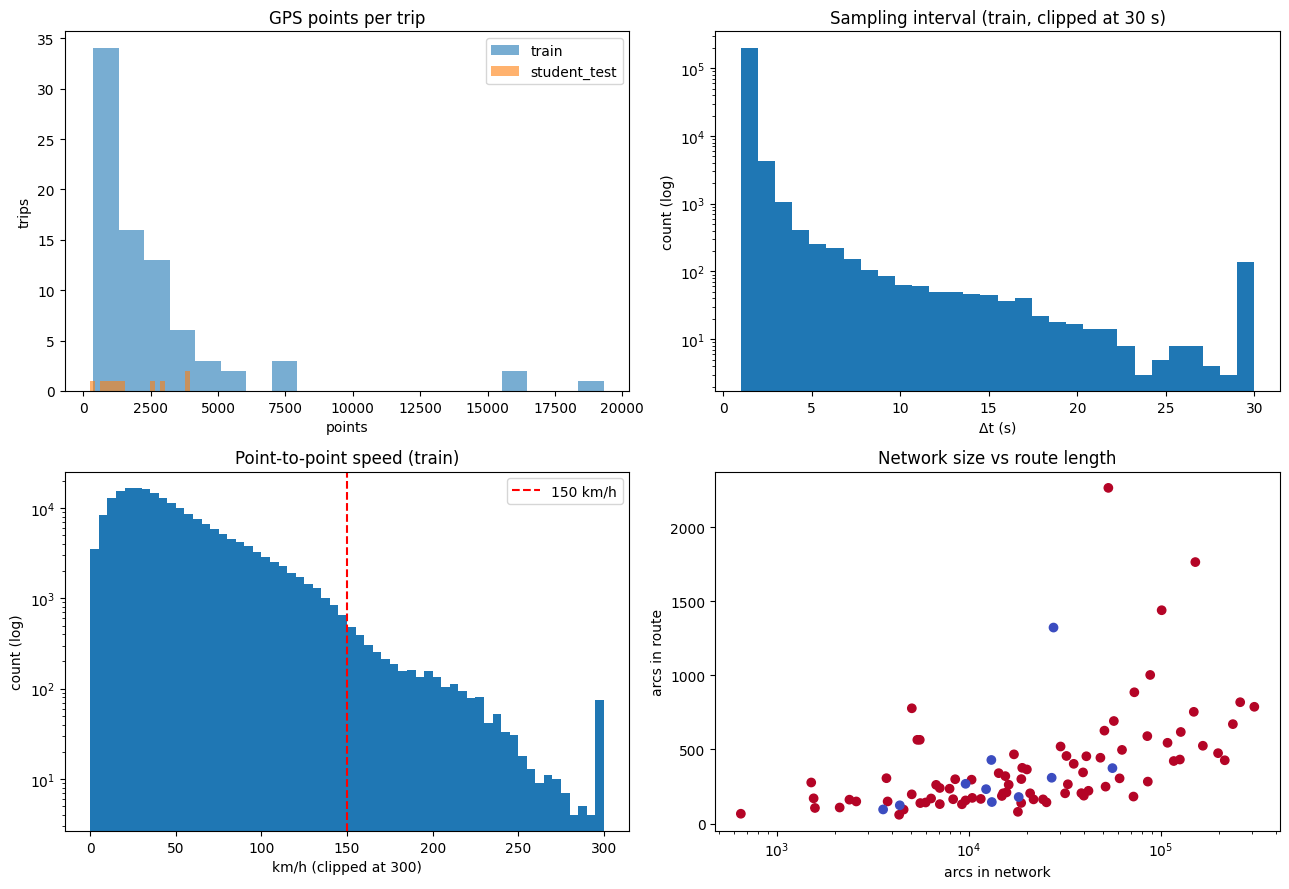

Share of train steps exactly 1 s: 96.5%
Share of train speeds > 150 km/h: 1.610%


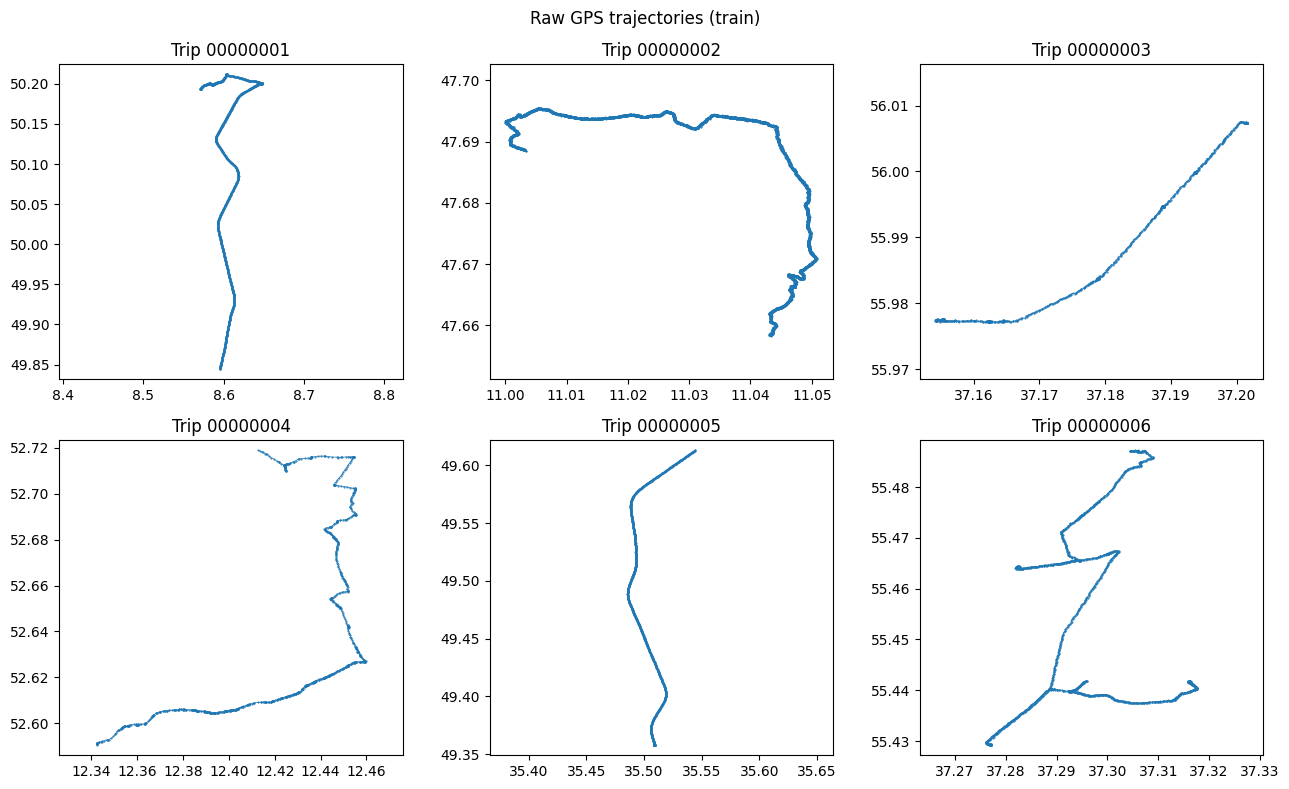

In [ ]:
import matplotlib.pyplot as plt

def load_track(partition, trip_id):
    return read_ws(os.path.join(DATA_ROOT, partition, trip_id, trip_id + ".track"), ["lon", "lat", "t"])

# Collect every time step and speed from the train partition
all_dt, all_speed = [], []
for t_id in trips["train"]:
    tr = load_track("train", t_id)
    dt = np.diff(tr.t.values)
    step = haversine_m(tr.lon.values[:-1], tr.lat.values[:-1], tr.lon.values[1:], tr.lat.values[1:])
    all_dt.append(dt); all_speed.append(step[dt > 0] / dt[dt > 0] * 3.6)
all_dt, all_speed = np.concatenate(all_dt), np.concatenate(all_speed)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for part in ["train", "student_test"]:
    ax[0, 0].hist(stats[stats.partition == part].n_points, bins=20, alpha=0.6, label=part)
ax[0, 0].set(title="GPS points per trip", xlabel="points", ylabel="trips"); ax[0, 0].legend()

ax[0, 1].hist(np.clip(all_dt, 0, 30), bins=30, log=True)
ax[0, 1].set(title="Sampling interval (train, clipped at 30 s)", xlabel="Δt (s)", ylabel="count (log)")

ax[1, 0].hist(np.clip(all_speed, 0, 300), bins=60, log=True)
ax[1, 0].axvline(150, color="r", ls="--", label="150 km/h")
ax[1, 0].set(title="Point-to-point speed (train)", xlabel="km/h (clipped at 300)", ylabel="count (log)"); ax[1, 0].legend()

ax[1, 1].scatter(stats.n_arcs, stats.route_len_arcs, c=(stats.partition == "train"), cmap="coolwarm")
ax[1, 1].set(title="Network size vs route length", xlabel="arcs in network", ylabel="arcs in route", xscale="log")
plt.tight_layout(); plt.savefig("eda_distributions.png", dpi=120); plt.show()

print(f"Share of train steps exactly 1 s: {100*np.mean(all_dt == 1):.1f}%")
print(f"Share of train speeds > 150 km/h: {100*np.mean(all_speed > 150):.3f}%")

# GPS trajectory shapes for 6 training trips
fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for a, t_id in zip(axs.flat, trips["train"][:6]):
    tr = load_track("train", t_id)
    a.plot(tr.lon, tr.lat, ".-", ms=1, lw=0.5); a.set_title(f"Trip {t_id}"); a.set_aspect("equal", adjustable="datalim")
plt.suptitle("Raw GPS trajectories (train)"); plt.tight_layout(); plt.savefig("gps_trajectories.png", dpi=120); plt.show()

In [ ]:
import folium

def trip_map(partition, trip_id, margin=0.003, max_arcs=4000):
    track, nodes, arcs, route = load_trip(partition, trip_id)
    m = folium.Map(location=[track.lat.mean(), track.lon.mean()], zoom_start=14, tiles="OpenStreetMap")

    # Road network: only arcs near the track (the full network is too large to draw)
    box = ((nodes.lon.between(track.lon.min() - margin, track.lon.max() + margin)) &
           (nodes.lat.between(track.lat.min() - margin, track.lat.max() + margin)))
    near = arcs[box.values[arcs.u] & box.values[arcs.v]].head(max_arcs)
    net = folium.FeatureGroup(name=f"Road network ({len(near)} arcs)")
    for u, v in zip(near.u, near.v):
        folium.PolyLine([(nodes.lat[u], nodes.lon[u]), (nodes.lat[v], nodes.lon[v])],
                        color="gray", weight=1, opacity=0.5).add_to(net)
    net.add_to(m)

    # Reference route: chain the arcs' node coordinates
    r = route.arc_id.values
    pts = [(nodes.lat[arcs.u[a]], nodes.lon[arcs.u[a]]) for a in r] + [(nodes.lat[arcs.v[r[-1]]], nodes.lon[arcs.v[r[-1]]])]
    ref = folium.FeatureGroup(name="Reference route")
    folium.PolyLine(pts, color="green", weight=5, opacity=0.8).add_to(ref); ref.add_to(m)

    # Raw GPS points
    gps = folium.FeatureGroup(name=f"Raw GPS ({len(track)} points)")
    for lat, lon in zip(track.lat, track.lon):
        folium.CircleMarker((lat, lon), radius=2, color="blue", fill=True).add_to(gps)
    gps.add_to(m)

    folium.Marker((track.lat.iloc[0], track.lon.iloc[0]), tooltip="Start", icon=folium.Icon(color="green")).add_to(m)
    folium.Marker((track.lat.iloc[-1], track.lon.iloc[-1]), tooltip="End", icon=folium.Icon(color="red")).add_to(m)
    folium.LayerControl().add_to(m)
    return m

m = trip_map("train", trips["train"][0])
m.save("map_train_00000001.html")
m

**Map observations (train trip 00000001):** blue = raw GPS, green = reference route,
gray = road network near the track, toggled with the layer control.
_(write: do GPS points sit beside the road rather than on it? where do they drift
toward parallel streets? any jumps?)_

## 2. Preprocessing
1. **Projection to metres.** Trips span several continents, so one global projection
   doesn't fit. Each trip is projected with a local equirectangular projection
   centred on the trip, accurate to well under 1% over a trip's extent (< 80 km).
2. **Gap segmentation.** A time gap > 60 s starts a new segment (up to about 1 km
   of unobserved driving), so continuity is not assumed across it.
3. **Heading and speed** are computed within a segment. Heading uses the previous→next
   point (central difference), which smooths GPS noise.
4. **Arc geometry:** length, bearing, and whether the reverse arc exists (two-way road).

In [ ]:
from scipy.spatial import cKDTree

R_EARTH = 6371000
GAP_S = 60   # gap (s) that starts a new segment

def project(lon, lat, lon0, lat0):
    """Local equirectangular projection to metres around the trip centre."""
    x = np.radians(lon - lon0) * R_EARTH * np.cos(np.radians(lat0))
    y = np.radians(lat - lat0) * R_EARTH
    return x, y

def point_to_segment(px, py, ax, ay, bx, by):
    """Distance from point(s) P to segment(s) AB, plus projection position t (0=A, 1=B)."""
    dx, dy = bx - ax, by - ay
    L2 = dx*dx + dy*dy
    t = ((px - ax)*dx + (py - ay)*dy) / np.where(L2 > 0, L2, 1)
    t = np.clip(np.where(L2 > 0, t, 0), 0, 1)
    return np.hypot(px - (ax + t*dx), py - (ay + t*dy)), t

def preprocess_trip(partition, trip_id):
    track, nodes, arcs, route = load_trip(partition, trip_id)
    lon0, lat0 = track.lon.mean(), track.lat.mean()
    track["x"], track["y"] = project(track.lon.values, track.lat.values, lon0, lat0)
    nodes["x"], nodes["y"] = project(nodes.lon.values, nodes.lat.values, lon0, lat0)

    # Time gaps -> segments
    track["dt"] = track.t.diff().fillna(0)
    track["segment"] = (track.dt > GAP_S).cumsum()

    # Speed and heading, computed within each segment only
    g = track.groupby("segment")
    step = np.hypot(g.x.diff(), g.y.diff())
    track["speed_mps"] = (step / track.dt.where(track.dt > 0)).fillna(0)
    hx = g.x.shift(-1).fillna(track.x) - g.x.shift(1).fillna(track.x)
    hy = g.y.shift(-1).fillna(track.y) - g.y.shift(1).fillna(track.y)
    track["heading"] = np.degrees(np.arctan2(hx, hy)) % 360        # 0 = north, clockwise
    track["heading_valid"] = np.hypot(hx, hy) > 2.0                 # False if (nearly) stationary

    # Arc geometry
    U, V = arcs.u.values, arcs.v.values
    arcs["ax"], arcs["ay"] = nodes.x.values[U], nodes.y.values[U]
    arcs["bx"], arcs["by"] = nodes.x.values[V], nodes.y.values[V]
    arcs["length_m"] = np.hypot(arcs.bx - arcs.ax, arcs.by - arcs.ay)
    arcs["bearing"] = np.degrees(np.arctan2(arcs.bx - arcs.ax, arcs.by - arcs.ay)) % 360
    arcs["key"] = U.astype(np.int64) * len(nodes) + V               # identifies (u, v); duplicates share it
    arcs["is_twoway"] = np.isin(V.astype(np.int64) * len(nodes) + U, arcs["key"].values)
    return track, nodes, arcs, route

## 3. Deriving per-point labels
`.route` is an ordered list of arcs, not one label per GPS point, so we derive one:
each GPS point is matched to the nearest route arc, searching **forward only**
from the previous match (window of 50 arcs). Moving forward respects the order of travel
and stops a point being matched to a later pass of the route over the same road.
`label_dist_m` (GPS-to-label distance) is kept as a label-quality measure.
Assumption: the reference route is close to, but not guaranteed to be, the true path.

In [ ]:
def label_points(track, arcs, route, cap=200.0):
    """Monotone alignment of GPS points to the ordered route arcs (dynamic programming).
    Minimises the total point-to-arc distance subject to arc_index[i] >= arc_index[i-1].
    Distances are capped at `cap` so off-route sections don't distort the alignment."""
    r = route.arc_id.values
    A = arcs[["ax", "ay", "bx", "by"]].values[r]
    px, py = track.x.values, track.y.values
    N, M = len(px), len(r)
    back = np.empty((N, M), dtype=np.int32)
    idx = np.arange(M)
    for i in range(N):
        d, _ = point_to_segment(px[i], py[i], A[:, 0], A[:, 1], A[:, 2], A[:, 3])
        d = np.minimum(d, cap)
        if i == 0:
            cost, back[0] = d, idx
        else:
            run_min = np.minimum.accumulate(cost)                          # best cost with prev index <= j
            back[i] = np.maximum.accumulate(np.where(cost == run_min, idx, 0))   # where that best came from
            cost = d + run_min
    # Backtrack the optimal path
    path = np.empty(N, dtype=np.int64)
    j = int(np.argmin(cost))
    for i in range(N - 1, -1, -1):
        path[i] = j
        j = back[i, j]
    ldist, _ = point_to_segment(px, py, A[path, 0], A[path, 1], A[path, 2], A[path, 3])
    return r[path], ldist

## 4. Candidate generation and features
Networks have up to 300k arcs, so checking every arc for every point is too slow.
Arcs are sampled every 10 m and stored in a KD-tree, and each GPS point queries it
within radius R. The exact point-to-segment distance is then computed and the K nearest
arcs are kept. Candidates are generated with a generous R = 100 m and K = 20 first,
so the final R and K can be **chosen from the candidate miss rate** (next section).

Features per (GPS point, candidate arc):
| Feature | Why |
|---|---|
| `dist_m` | GPS noise is mostly small, so the true road is usually close |
| `dist_rank`, `dist_minus_min` | Closeness relative to the other candidates of the same point |
| `heading_diff` (0–180°) | Direction of travel vs arc direction; the only feature that separates the two directions of a two-way road |
| `heading_valid` | Heading is meaningless when stationary (heading_diff set to a neutral 90°) |
| `n_cands` | Dense areas (junctions, parallel streets) are more ambiguous |
| `arc_length_m`, `proj_frac`, `at_endpoint` | Where the projection falls on the arc; endpoint projections are typical of the wrong arc near junctions |
| `is_twoway` | Whether a twin arc in the opposite direction exists |
| `speed_mps`, `dt` | Context: fast or after a gap means larger position uncertainty |

**Deliberately excluded:** raw lon/lat and x/y (location-specific; trips are in different
cities, so these would not generalise), trip id, arc id, timestamp.

In [ ]:
RADIUS_GEN, K_GEN, DENSIFY_M = 100, 20, 10

def generate_candidates(track, arcs, radius=RADIUS_GEN, k=K_GEN):
    # 1. Keep only arcs whose bounding box comes within `radius` of the track
    xmin, xmax = track.x.min() - radius, track.x.max() + radius
    ymin, ymax = track.y.min() - radius, track.y.max() + radius
    near = arcs[(np.minimum(arcs.ax, arcs.bx) <= xmax) & (np.maximum(arcs.ax, arcs.bx) >= xmin) &
                (np.minimum(arcs.ay, arcs.by) <= ymax) & (np.maximum(arcs.ay, arcs.by) >= ymin)]
    ax_, ay_, bx_, by_ = (near[c].values for c in ["ax", "ay", "bx", "by"])

    # 2. Sample a point every DENSIFY_M along each arc and index them in a KD-tree
    n = np.maximum(1, np.ceil(near.length_m.values / DENSIFY_M)).astype(int)
    cnt = n + 1
    owner = np.repeat(np.arange(len(near)), cnt)
    frac = (np.arange(cnt.sum()) - np.repeat(np.cumsum(cnt) - cnt, cnt)) / np.repeat(n, cnt)
    sx = ax_[owner] + frac * (bx_ - ax_)[owner]
    sy = ay_[owner] + frac * (by_ - ay_)[owner]
    tree = cKDTree(np.c_[sx, sy])
    hits = tree.query_ball_point(np.c_[track.x.values, track.y.values], r=radius + DENSIFY_M / 2)

    # 3. Unique arcs per GPS point, then the exact distance
    pts, cands = [], []
    for i, h in enumerate(hits):
        if h:
            u = np.unique(owner[h]); pts.append(np.full(len(u), i)); cands.append(u)
    pts, cands = np.concatenate(pts), np.concatenate(cands)
    d, tproj = point_to_segment(track.x.values[pts], track.y.values[pts],
                                ax_[cands], ay_[cands], bx_[cands], by_[cands])
    c = pd.DataFrame({"point": pts, "arc": near.index.values[cands], "dist_m": d, "proj_frac": tproj})
    c = c[c.dist_m <= radius].copy()
    c["dist_rank"] = c.groupby("point").dist_m.rank(method="first").astype(int) - 1
    return c[c.dist_rank < k].reset_index(drop=True)

def build_features(c, track, arcs, labels):
    p, a = c.point.values, c.arc.values
    c["n_cands"] = c.groupby("point").arc.transform("size")
    c["dist_minus_min"] = c.dist_m - c.groupby("point").dist_m.transform("min")
    hd = np.abs(track.heading.values[p] - arcs.bearing.values[a]) % 360
    c["heading_diff"] = np.minimum(hd, 360 - hd)
    c["heading_valid"] = track.heading_valid.values[p].astype(int)
    c.loc[c.heading_valid == 0, "heading_diff"] = 90.0
    c["arc_length_m"] = arcs.length_m.values[a]
    c["is_twoway"] = arcs.is_twoway.values[a].astype(int)
    c["at_endpoint"] = ((c.proj_frac <= 0) | (c.proj_frac >= 1)).astype(int)
    c["speed_mps"] = track.speed_mps.values[p]
    c["dt"] = track.dt.values[p]
    c["segment"] = track.segment.values[p]
    # Label: candidate equals the reference arc (duplicate arcs with the same endpoints also count)
    c["y"] = (arcs.key.values[a] == arcs.key.values[labels[p]]).astype(int)
    return c

In [ ]:
import time
feat_list, point_list = [], []
t0 = time.time()
for part in ["train", "student_test"]:
    for trip_id in trips[part]:
        track, nodes, arcs, route = preprocess_trip(part, trip_id)
        labels, ldist = label_points(track, arcs, route)
        c = build_features(generate_candidates(track, arcs), track, arcs, labels)
        c["trip"], c["partition"] = trip_id, part
        feat_list.append(c)
        point_list.append(pd.DataFrame({"partition": part, "trip": trip_id, "point": np.arange(len(track)),
                                        "label_arc": labels, "label_dist_m": ldist}))
    print(f"{part} done after {time.time() - t0:.0f} s")

feats = pd.concat(feat_list, ignore_index=True)
points = pd.concat(point_list, ignore_index=True)
print("candidate rows:", feats.shape, "| GPS points:", len(points))
print("\nLabel quality: GPS distance to its labelled arc (m)")
print(points.groupby("partition").label_dist_m.describe(percentiles=[.5, .9, .95, .99]).round(1))

train done after 42 s
student_test done after 45 s
candidate rows: (2883376, 18) | GPS points: 227577

Label quality: GPS distance to its labelled arc (m)
                 count  mean   std  min  50%   90%    95%    99%    max
partition                                                              
student_test   19160.0   6.7   6.9  0.0  5.3  13.4   16.8   28.0  157.9
train         208417.0  22.3  49.5  0.0  5.7  89.3  142.0  205.4  644.6


In [ ]:
# Per GPS point: distance and rank of its true arc among the candidates (NaN if not found)
pos = (feats[feats.y == 1].groupby(["partition", "trip", "point"])
       .agg(true_dist=("dist_m", "min"), true_rank=("dist_rank", "min")).reset_index())
pp = points.merge(pos, on=["partition", "trip", "point"], how="left")
tr_pp, tr_f = pp[pp.partition == "train"], feats[feats.partition == "train"]

rows = []
for R in [20, 30, 50, 75, 100]:
    for K in [5, 10, 20]:
        hit = (tr_pp.true_dist <= R) & (tr_pp.true_rank < K)
        sel = tr_f[(tr_f.dist_m <= R) & (tr_f.dist_rank < K)]
        rows.append({"R_m": R, "K": K, "miss_rate_%": round(100 * (1 - hit.mean()), 2),
                     "avg_cands": round(sel.groupby(["trip", "point"]).size().mean(), 1)})
miss = pd.DataFrame(rows)
miss.to_csv("candidate_miss_rate.csv", index=False)
print(miss.pivot(index="R_m", columns="K", values=["miss_rate_%", "avg_cands"]))

    miss_rate_%               avg_cands           
K            5      10     20        5    10    20
R_m                                               
20        15.47  14.61  14.47       3.2  3.9   4.1
30        13.82  12.74  12.55       3.7  5.0   5.6
50        12.95  11.74  11.42       4.2  6.5   8.6
75        12.56  11.27  10.92       4.4  7.5  11.1
100       12.39  10.92  10.55       4.5  7.8  12.6


**Choosing R and K:** a larger R or K lowers the candidate miss rate (true arc absent,
which no model can recover from) but adds more negative candidates (harder classification,
slower HMM). We pick the smallest R and K where the miss rate levels off.
Chosen: R = __ m, K = __ (fill in from the table above). Decided on train only.

In [ ]:
def global_route_dist(track, arcs, route, chunk=2000):
    """Distance from each GPS point to the closest arc anywhere on the route (order ignored)."""
    A = arcs[["ax", "ay", "bx", "by"]].values[route.arc_id.values]
    out = np.empty(len(track))
    for s in range(0, len(track), chunk):
        px = track.x.values[s:s+chunk, None]; py = track.y.values[s:s+chunk, None]
        d, _ = point_to_segment(px, py, A[None, :, 0], A[None, :, 1], A[None, :, 2], A[None, :, 3])
        out[s:s+chunk] = d.min(axis=1)
    return out

gd = []
for part in ["train", "student_test"]:
    for trip_id in trips[part]:
        track, nodes, arcs, route = preprocess_trip(part, trip_id)
        gd.append(global_route_dist(track, arcs, route))
points["global_dist_m"] = np.concatenate(gd)      # same trip order as `points`
points["rel_pos"] = points.groupby("trip").point.transform(lambda s: s / s.max())

for thr in [50, 100]:
    print(f"\n% of points farther than {thr} m:")
    print(pd.DataFrame({
        "labelled_arc": points.groupby("partition").label_dist_m.apply(lambda s: round(100*(s > thr).mean(), 2)),
        "nearest_route_arc": points.groupby("partition").global_dist_m.apply(lambda s: round(100*(s > thr).mean(), 2)),
    }))

far = points[points.label_dist_m > 50]
print("\nTrips with the most far-labelled points:")
print(far.groupby(["partition", "trip"]).size().sort_values(ascending=False).head(10))
print("\nWhere in the trip are far points? (0 = start, 1 = end)")
print(np.histogram(far.rel_pos, bins=10, range=(0, 1))[0])


% of points farther than 50 m:
              labelled_arc  nearest_route_arc
partition                                    
student_test          0.14               0.14
train                11.16              10.82

% of points farther than 100 m:
              labelled_arc  nearest_route_arc
partition                                    
student_test          0.09               0.02
train                 9.85               9.59

Trips with the most far-labelled points:
partition  trip    
train      00000054    17274
           00000033     3440
           00000002      868
           00000084      593
           00000066      390
           00000043      165
           00000096      145
           00000081      142
           00000019       39
           00000020       36
dtype: int64

Where in the trip are far points? (0 = start, 1 = end)
[ 982 2091 2093 2314 2607 2547 2542 3007 2461 2638]


In [ ]:
LABEL_MAX_M = 50   # label more than 50 m from the GPS point = unreliable (GPS off the reference route)
points["label_ok"] = points.label_dist_m <= LABEL_MAX_M
feats = feats.drop(columns=["label_ok"], errors="ignore").merge(
    points[["partition", "trip", "point", "label_ok"]], on=["partition", "trip", "point"], how="left")

print("% of points with a reliable label:")
print((100 * points.groupby("partition").label_ok.mean()).round(2))
print("\nTrips with < 80% reliable labels:")
print(points.groupby(["partition", "trip"]).label_ok.mean().loc[lambda s: s < 0.8].round(2))

# Miss rate on reliable train points only
pos = (feats[feats.y == 1].groupby(["partition", "trip", "point"])
       .agg(true_dist=("dist_m", "min"), true_rank=("dist_rank", "min")).reset_index())
pp = points.merge(pos, on=["partition", "trip", "point"], how="left")
tr_pp = pp[(pp.partition == "train") & pp.label_ok]
tr_f = feats[(feats.partition == "train") & feats.label_ok]
rows = []
for R in [20, 30, 50, 75, 100]:
    for K in [5, 10, 20]:
        hit = (tr_pp.true_dist <= R) & (tr_pp.true_rank < K)
        sel = tr_f[(tr_f.dist_m <= R) & (tr_f.dist_rank < K)]
        rows.append({"R_m": R, "K": K, "miss_rate_%": round(100 * (1 - hit.mean()), 2),
                     "avg_cands": round(sel.groupby(["trip", "point"]).size().mean(), 1)})
miss = pd.DataFrame(rows); miss.to_csv("candidate_miss_rate.csv", index=False)
print(miss.pivot(index="R_m", columns="K", values=["miss_rate_%", "avg_cands"]))

% of points with a reliable label:
partition
student_test    99.86
train           88.84
Name: label_ok, dtype: float64

Trips with < 80% reliable labels:
partition  trip    
train      00000033    0.41
           00000054    0.11
Name: label_ok, dtype: float64
    miss_rate_%             avg_cands           
K            5     10    20        5    10    20
R_m                                             
20         4.85  3.88  3.73       3.2  3.9   4.1
30         3.00  1.78  1.56       3.7  5.0   5.7
50         2.02  0.66  0.30       4.2  6.5   8.6
75         2.02  0.66  0.30       4.4  7.5  11.3
100        2.02  0.66  0.30       4.6  8.1  13.1


Final candidate rows: (1360338, 19) | train rows with reliable labels: 1200125
Positive rate: 15.3%

Baseline 'nearest arc' Top-1 accuracy (train, reliable): 55.5%
Baseline 'nearest arc' Top-1 accuracy (student_test):    53.5%


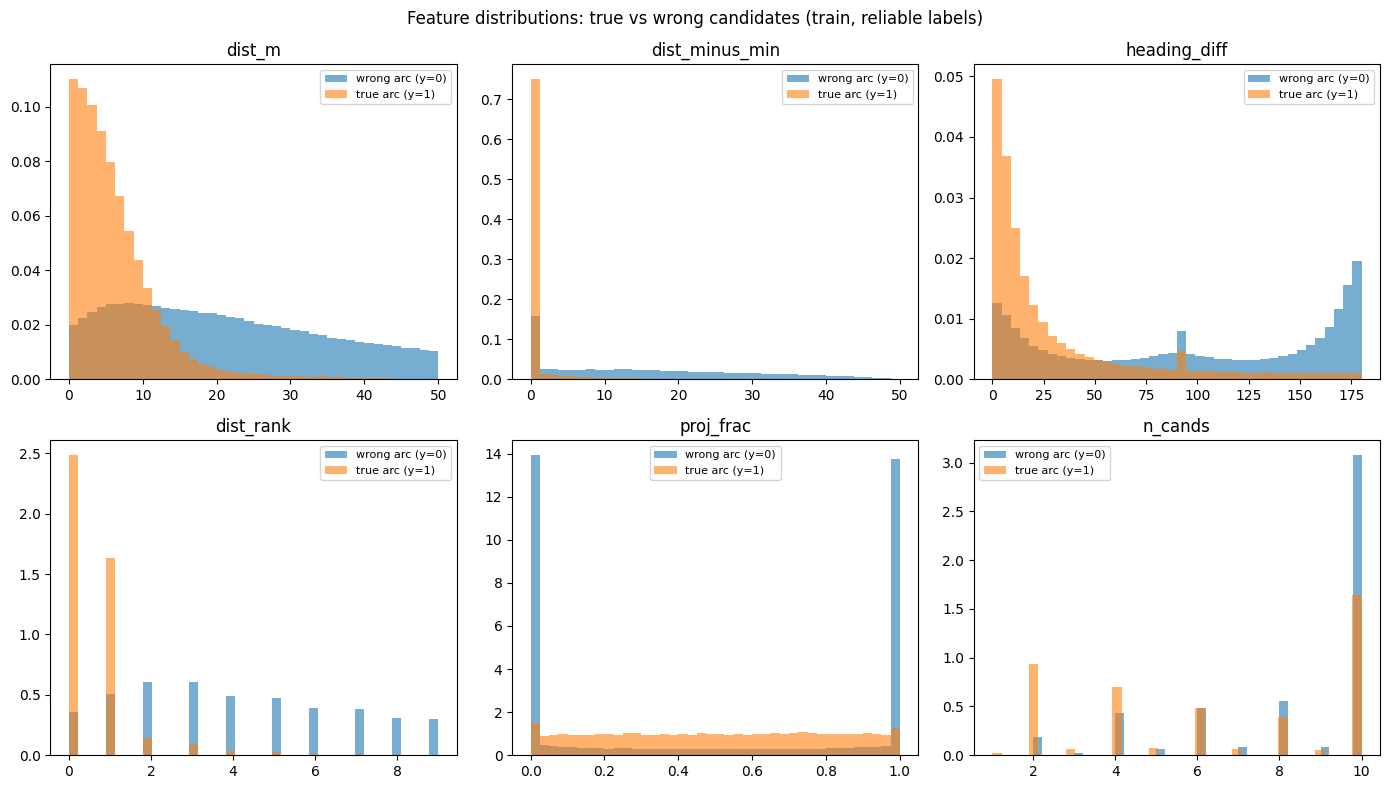

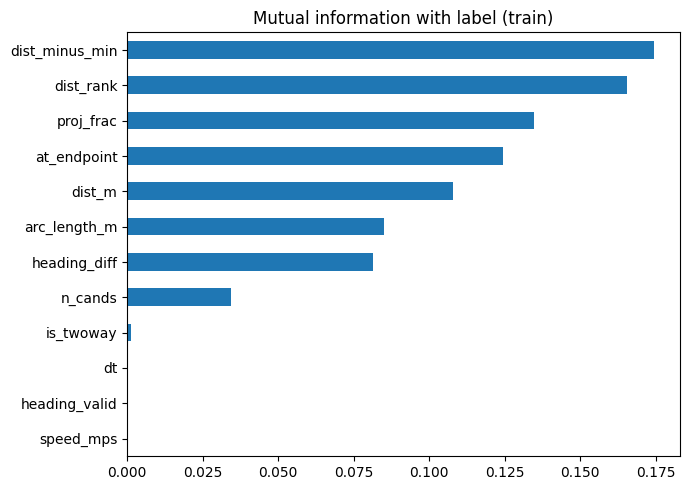

dist_minus_min    0.1743
dist_rank         0.1656
proj_frac         0.1347
at_endpoint       0.1245
dist_m            0.1078
arc_length_m      0.0851
heading_diff      0.0812
n_cands           0.0344
is_twoway         0.0011
dt                0.0002
heading_valid     0.0000
speed_mps         0.0000
dtype: float64


In [ ]:
from sklearn.feature_selection import mutual_info_classif

R_FINAL, K_FINAL = 50, 10
final = feats[(feats.dist_m <= R_FINAL) & (feats.dist_rank < K_FINAL)].copy()
final["n_cands"] = final.groupby(["partition", "trip", "point"]).arc.transform("size")   # recount after filtering

FEATURES = ["dist_m", "dist_rank", "dist_minus_min", "heading_diff", "heading_valid", "n_cands",
            "arc_length_m", "proj_frac", "at_endpoint", "is_twoway", "speed_mps", "dt"]
DISCRETE = ["dist_rank", "heading_valid", "n_cands", "at_endpoint", "is_twoway"]

tr = final[(final.partition == "train") & final.label_ok]
print("Final candidate rows:", final.shape, "| train rows with reliable labels:", len(tr))
print(f"Positive rate: {100*tr.y.mean():.1f}%")

# Simple baseline: always pick the nearest arc
print(f"\nBaseline 'nearest arc' Top-1 accuracy (train, reliable): {100*tr[tr.dist_rank == 0].y.mean():.1f}%")
print(f"Baseline 'nearest arc' Top-1 accuracy (student_test):    "
      f"{100*final[(final.partition=='student_test') & final.label_ok & (final.dist_rank==0)].y.mean():.1f}%")

# Feature distributions: true arc vs wrong arcs
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, f in zip(axs.flat, ["dist_m", "dist_minus_min", "heading_diff", "dist_rank", "proj_frac", "n_cands"]):
    ax.hist(tr.loc[tr.y == 0, f], bins=40, alpha=0.6, density=True, label="wrong arc (y=0)")
    ax.hist(tr.loc[tr.y == 1, f], bins=40, alpha=0.6, density=True, label="true arc (y=1)")
    ax.set_title(f); ax.legend(fontsize=8)
plt.suptitle("Feature distributions: true vs wrong candidates (train, reliable labels)")
plt.tight_layout(); plt.savefig("feature_distributions.png", dpi=120); plt.show()

# Mutual information with the label (200k-row sample for speed)
s = tr.sample(200_000, random_state=42)
mi = mutual_info_classif(s[FEATURES], s.y, discrete_features=[f in DISCRETE for f in FEATURES], random_state=42)
mi = pd.Series(mi, index=FEATURES).sort_values(ascending=False)
mi.to_csv("feature_mutual_information.csv")
mi.plot.barh(figsize=(7, 5), title="Mutual information with label (train)"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig("feature_mi.png", dpi=120); plt.show()
print(mi.round(4))

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
OUT = "/content/drive/MyDrive/pathsnap"
os.makedirs(OUT, exist_ok=True)
final.to_parquet(f"{OUT}/features_R50_K10.parquet", index=False)
points.to_csv(f"{OUT}/point_labels.csv", index=False)
for f in ["dataset_summary.csv", "candidate_miss_rate.csv", "feature_mutual_information.csv",
          "feature_distributions.png", "feature_mi.png"]:
    if os.path.exists(f): os.system(f"cp '{f}' {OUT}/")
print(os.listdir(OUT))

Mounted at /content/drive
['features_R50_K10.parquet', 'point_labels.csv', 'dataset_summary.csv', 'candidate_miss_rate.csv', 'feature_mutual_information.csv', 'feature_distributions.png', 'feature_mi.png']


In [ ]:
def top1(df, score_cols, ascending):
    """Top-1 accuracy: per point, pick the candidate with the best score; is it the true arc?"""
    best = df.sort_values(score_cols, ascending=ascending).groupby(["trip", "point"]).head(1)
    return 100 * best.y.mean()

for part in ["train", "student_test"]:
    d = final[(final.partition == part) & final.label_ok].copy()
    d["dist_round"] = d.dist_m.round(0)                      # treat distances within ~1 m as tied
    print(f"{part:13s} nearest arc: {top1(d, ['dist_m'], [True]):.1f}% | "
          f"nearest + heading tie-break: {top1(d, ['dist_round', 'heading_diff'], [True, True]):.1f}%")

FINAL_FEATURES = ["dist_m", "dist_rank", "dist_minus_min", "heading_diff", "proj_frac",
                  "at_endpoint", "arc_length_m", "n_cands", "is_twoway"]
print("\nSelected features:", FINAL_FEATURES)

train         nearest arc: 55.6% | nearest + heading tie-break: 79.1%
student_test  nearest arc: 54.8% | nearest + heading tie-break: 80.8%

Selected features: ['dist_m', 'dist_rank', 'dist_minus_min', 'heading_diff', 'proj_frac', 'at_endpoint', 'arc_length_m', 'n_cands', 'is_twoway']


## 5. Feature selection
- Nearest-arc baseline Top-1 is only ~55% (train 55.5%, student_test 53.5%): two-way roads
  are stored as twin arcs with identical geometry, so distance alone can't choose between them.
- `heading_diff` separates them: true arcs ~0°, wrong twins ~180°. Its single-feature MI
  understates this because it matters exactly when distances are tied (interaction effect).
  Tie-break experiment: __% → __%.
- `proj_frac` / `at_endpoint`: wrong arcs at junctions project onto their shared endpoint.
- Relative distance (`dist_minus_min`, `dist_rank`) > absolute distance (`dist_m`).
- **Dropped:** `speed_mps`, `dt`, `heading_valid` (MI ≈ 0). They are the same for all candidates
  of a point, so they can't rank candidates; still used for segmentation and the HMM.
- `is_twoway` (MI 0.001): kept for now, to be tested with/without in model experiments.
- **Final features (9):** dist_m, dist_rank, dist_minus_min, heading_diff, proj_frac,
  at_endpoint, arc_length_m, n_cands, is_twoway.

In [ ]:
mv_rows = []
for part in ["train", "student_test"]:
    for ftype, names in [(".track", ["lon", "lat", "t"]), (".nodes", ["lon", "lat"]),
                         (".arcs", ["u", "v"]), (".route", ["arc_id"])]:
        n_rows, n_missing, n_nonnumeric = 0, 0, 0
        for t_id in trips[part]:
            path = os.path.join(DATA_ROOT, part, t_id, t_id + ftype)
            raw = pd.read_csv(path, sep=r"\s+", header=None, names=names, dtype=str)
            n_rows += len(raw)
            n_missing += int(raw.isna().sum().sum())
            n_nonnumeric += int(raw.apply(pd.to_numeric, errors="coerce").isna().sum().sum()) - int(raw.isna().sum().sum())
        mv_rows.append({"partition": part, "file": ftype, "rows": n_rows,
                        "missing_values": n_missing, "non_numeric_values": n_nonnumeric})
missing = pd.DataFrame(mv_rows)
missing.to_csv("missing_value_analysis.csv", index=False)
print(missing.to_string(index=False))

   partition   file    rows  missing_values  non_numeric_values
       train .track  208417               0                   0
       train .nodes 1933485               0                   0
       train  .arcs 3876904               0                   0
       train .route   31336               0                   0
student_test .track   19160               0                   0
student_test .nodes   90689               0                   0
student_test  .arcs  185041               0                   0
student_test .route    3477               0                   0


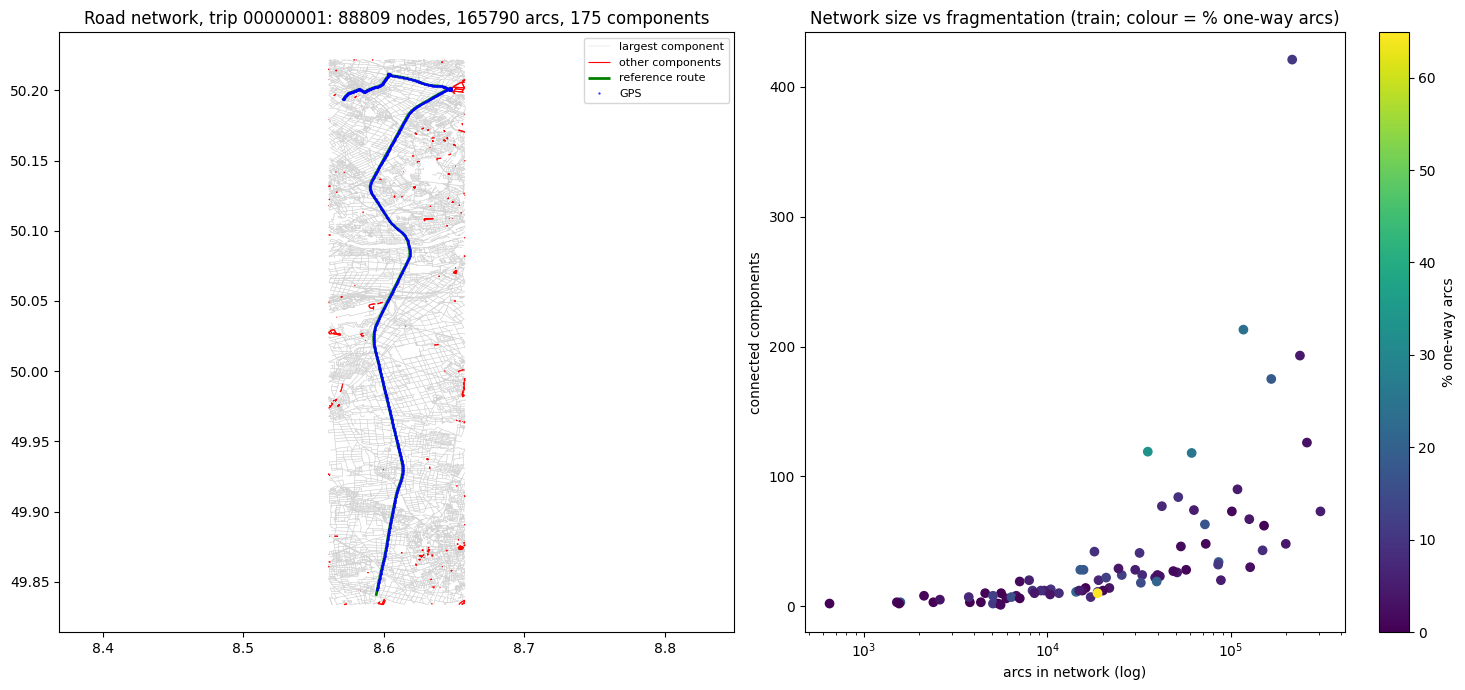

Largest component share of nodes: 97.8 %
Component sizes (top 10): [86854, 127, 80, 56, 49, 48, 46, 38, 37, 35]


In [ ]:
from matplotlib.collections import LineCollection

track, nodes, arcs, route = load_trip("train", trips["train"][0])
G = nx.DiGraph(); G.add_nodes_from(range(len(nodes))); G.add_edges_from(zip(arcs.u, arcs.v))
comps = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
comp_id = np.empty(len(nodes), dtype=int)
for k, c in enumerate(comps): comp_id[list(c)] = k

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
# Left: whole network, largest component gray, the other components red
segs = np.stack([nodes[["lon", "lat"]].values[arcs.u], nodes[["lon", "lat"]].values[arcs.v]], axis=1)
main = comp_id[arcs.u.values] == 0
ax[0].add_collection(LineCollection(segs[main], colors="lightgray", linewidths=0.3, label="largest component"))
ax[0].add_collection(LineCollection(segs[~main], colors="red", linewidths=0.8, label="other components"))
r = route.arc_id.values
ax[0].add_collection(LineCollection(segs[r], colors="green", linewidths=2, label="reference route"))
ax[0].plot(track.lon, track.lat, ".", ms=1, color="blue", label="GPS")
ax[0].autoscale(); ax[0].set_aspect("equal", adjustable="datalim"); ax[0].legend(loc="upper right", fontsize=8)
ax[0].set_title(f"Road network, trip {trips['train'][0]}: {len(nodes)} nodes, {len(arcs)} arcs, {len(comps)} components")

# Right: network size and connectivity across all train trips
tr_stats = stats[stats.partition == "train"]
ax[1].scatter(tr_stats.n_arcs, tr_stats.n_components, c=tr_stats.pct_oneway_arcs, cmap="viridis")
ax[1].set(xscale="log", xlabel="arcs in network (log)", ylabel="connected components",
          title="Network size vs fragmentation (train; colour = % one-way arcs)")
plt.colorbar(ax[1].collections[0], ax=ax[1], label="% one-way arcs")
plt.tight_layout(); plt.savefig("road_network.png", dpi=120); plt.show()

print("Largest component share of nodes:", round(100 * len(comps[0]) / len(nodes), 1), "%")
print("Component sizes (top 10):", [len(c) for c in comps[:10]])